# Estimating infiltration from soil survey data for overland flow

modeling

Corey T. White  
2026-09-30

# Introduction

In this tutorial, we will estimate soil infiltration from USDA soil
survey data and use it to drive overland flow simulations with the SIMWE
model at a 52 ha research site in Raleigh, North Carolina.

[r.sim.water](https://grass.osgeo.org/grass-stable/manuals/r.sim.water.html)
accepts infiltration two ways: by setting the rainfall excess rate,
where **rainfall excess** is `rainfall - infiltration`, or by setting
the **infiltration rate** in mm/hr applied to water already crossing a
cell. Both are commonly set to a single value for an entire study area
through the `rain_value` and `infil_value` parameters, or defined by a
spatially variable raster through `rain` and `infil`.

During this tutorial we approximate the infiltration rate (`infil`)
using the USDA SSURGO soil survey dataset, which supplies texture, bulk
density, and horizon depths. From those measurements we estimate
saturated hydraulic conductivity (Ksat) with a pedotransfer function
(ROSETTA). To do this we will follow the steps outlined below.

1.  Import USDA SSURGO soil texture and Ksat with
    [r.in.ssurgo](https://grass.osgeo.org/grass-stable/manuals/addons/r.in.ssurgo.html)
2.  Estimate Ksat with
    [r.soils.rosetta](https://grass.osgeo.org/grass-stable/manuals/addons/r.soils.rosetta.html),
    which implements the ROSETTA pedotransfer model
3.  Run
    [r.sim.water](https://grass.osgeo.org/grass-stable/manuals/r.sim.water.html)
    three times, with a single infiltration value, with the estimated
    Ksat field, and with the Ksat SSURGO reports directly

Additional concepts covered in this tutorial:

- Downloading and initializing a published GRASS sample project
- Querying the Soil Data Access web service from the computational
  region
- Depth-weighted aggregation of soil horizon data
- Deriving Manning’s n from land cover
- Comparing simulation runs that differ in one input

The study site is the North Carolina State University Sediment and
Erosion Control Research and Education Facility (SECREF). The data come
from a GRASS sample dataset assembled for SIMWE work (Petrasova 2026).

> **How to run this tutorial?**
>
> This tutorial is prepared to be run in a Jupyter notebook locally or
> using services such as Google Colab. You can [download the notebook
> here](soil_informed_overland_flow.ipynb).
>
> If you are not sure how to get started with GRASS, check out the
> tutorials [Get started with GRASS & Python in Jupyter
> Notebooks](../get_started/fast_track_grass_and_python.qmd) and [Get
> started with GRASS in Google
> Colab](../get_started/grass_gis_in_google_colab.qmd).

For the empirical alternative to this workflow, the [SIMWE
parallelization tutorial](../parallelization/SIMWE_parallelization.qmd)
derives runoff from the SCS Curve Number method instead.

# Setup

Start with importing Python packages. To import the *grass* package, you
need to tell Python where the GRASS Python package is (can be skipped
for some environments).

In [1]:
import io
import os
import sys
import subprocess
from pathlib import Path

sys.path.append(
    subprocess.check_output(["grass", "--config", "python_path"], text=True).strip()
)

import pandas as pd

import grass.script as gs
import grass.jupyter as gj
from grass.tools import Tools

`r.soils.rosetta` runs the offline
[rosetta-soil](https://pypi.org/project/rosetta-soil/) package when it
is installed and falls back to a web API when it is not. Install it to
keep the run reproducible and to enable the uncertainty outputs.

The plots later in the tutorial use pandas, seaborn, and matplotlib.

In [2]:
!pip install rosetta-soil pandas seaborn matplotlib

The maps below place their legend outside the map frame. `d.legend`
draws inside the frame, so each figure widens the computational region
with
[RegionManager](https://grass.osgeo.org/grass-stable/manuals/libpython/grass.script.html#grass.script.RegionManager)
and draws the legend into the empty map that creates.

In [3]:
FONT = "OpenSans-Regular"

# Adding 150 m to the south of the 750 m region puts the legend in the bottom
# 150 / 900 = 16.7% of the frame. Blank that strip so vectors do not run into it.
BLANK = """color 240:240:241
polygon
 0 0
 100 0
 100 16.7
 0 16.7
"""

# 400 m added to the west of the 700 m region is the left 36.4% of the frame
BLANK_WEST = """color 240:240:241
polygon
 0 0
 36.4 0
 36.4 100
 0 100
"""

## Download the sample dataset

The SECREF project is a complete GRASS project in EPSG:6542 (NAD83(2011)
/ North Carolina, meters) at 1 m resolution. We download it from Zenodo
and unpack it.

In [4]:
import urllib.request
import zipfile

url = (
    "https://zenodo.org/api/records/23017720/files/"
    "secref_northcarolina_usa_epsg6542.zip/content"
)
grassdata = Path("grassdata")
grassdata.mkdir(exist_ok=True)

urllib.request.urlretrieve(url, "secref.zip")
with zipfile.ZipFile("secref.zip") as archive:
    archive.extractall(grassdata)

The download is about 24 MB. We will work in a new mapset so that the
published PERMANENT mapset stays as distributed.

In [5]:
mapset_path = grassdata / "secref_northcarolina_usa_epsg6542" / "work"
gs.create_mapset(mapset_path)
session = gj.init(mapset_path)
tools = Tools()

With a session running we can install the two addons this tutorial uses.

In [6]:
tools.g_extension(extension="r.in.ssurgo")
tools.g_extension(extension="r.soils.rosetta")

The project contains six rasters and three vectors:

In [7]:
pd.DataFrame(
    [
        {
            "type": kind,
            "maps": ", ".join(
                m["name"]
                for m in tools.g_list(
                    type=kind, mapset="PERMANENT", format="json"
                ).json
            ),
        }
        for kind in ["raster", "vector"]
    ]
)

| type   | maps                                                 |
|:-------|:-----------------------------------------------------|
| raster | elevation, landcover, naip.1, naip.2, naip.3, naip.4 |
| vector | roads, soils, streams                                |

We set the computational region to the elevation map. Everything that
follows inherits this region, 700 by 750 cells at 1 m.

In [8]:
tools.g_region(raster="elevation")

region = tools.g_region(flags="p", format="json").json
pd.DataFrame(
    [{"setting": "CRS", "value": region["crs"]["name"]}]
    + [
        {"setting": key, "value": region[key]}
        for key in ["north", "south", "west", "east",
                    "nsres", "ewres", "rows", "cols", "cells"]
    ]
)

| setting | value                        |
|:--------|:-----------------------------|
| CRS     | NAD83(2011) / North Carolina |
| north   | 220750                       |
| south   | 220000                       |
| west    | 638300                       |
| east    | 639000                       |
| nsres   | 1                            |
| ewres   | 1                            |
| rows    | 750                          |
| cols    | 700                          |
| cells   | 525000                       |

# The study area

SECREF is on a low Piedmont ridge draining to two small streams. The 0.6
m USDA National Agriculture Imagery Program (NAIP) imagery shows the
research plots, gravel access roads, and wooded margins.

In [9]:
site = gj.Map(width=900, font=FONT, use_region=True)
site.d_rgb(red="naip.1", green="naip.2", blue="naip.3")
site.d_vect(map="streams", color="30:120:220", width=2)
site.d_barscale(
    at=(4, 7),
    flags="n",
    fontsize=18,
    length=200, units="meters",
    style="down_ticks",
    color="white", bgcolor="none",
    width_scale=1.5, font="OpenSans-Bold"
)
site.show()

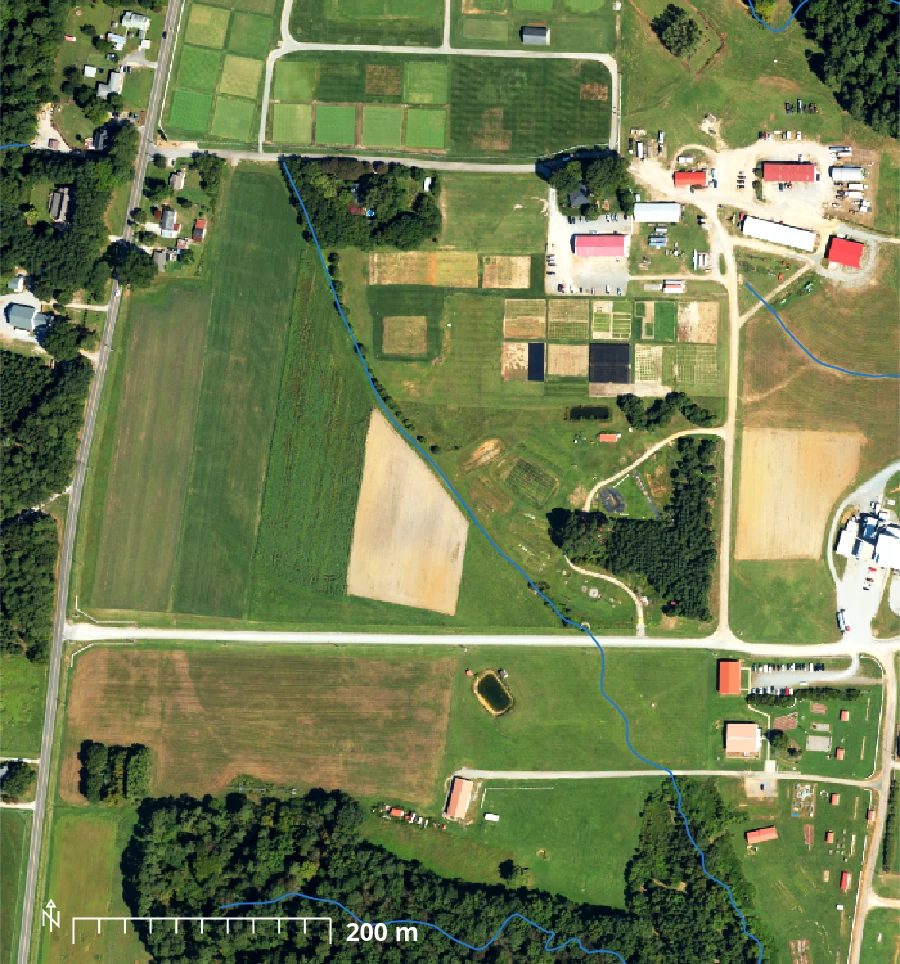

Relief across the site spans 29 m, from 102.6 m to 131.6 m. We create a
shaded relief map with
[r.relief](https://grass.osgeo.org/grass-stable/manuals/r.relief.html)
and use it as the base for the maps that follow.

In [10]:
tools.r_relief(input="elevation", output="relief", zscale=2)
tools.r_colors(map="elevation", color="elevation")

with gs.RegionManager(s="s-150"):
    dem = gj.Map(width=900, height=1157, font=FONT, use_region=True)
    dem.d_shade(shade="relief", color="elevation", brighten=30)
    dem.d_vect(map="streams", color="30:120:220", width=2)
    dem.d_graph(stdin=io.StringIO(BLANK))
    dem.d_legend(raster="elevation", title="Elevation (m)", at=(4, 9, 10, 90),
                 flags="st", fontsize=18, title_fontsize=22)
    dem.show()

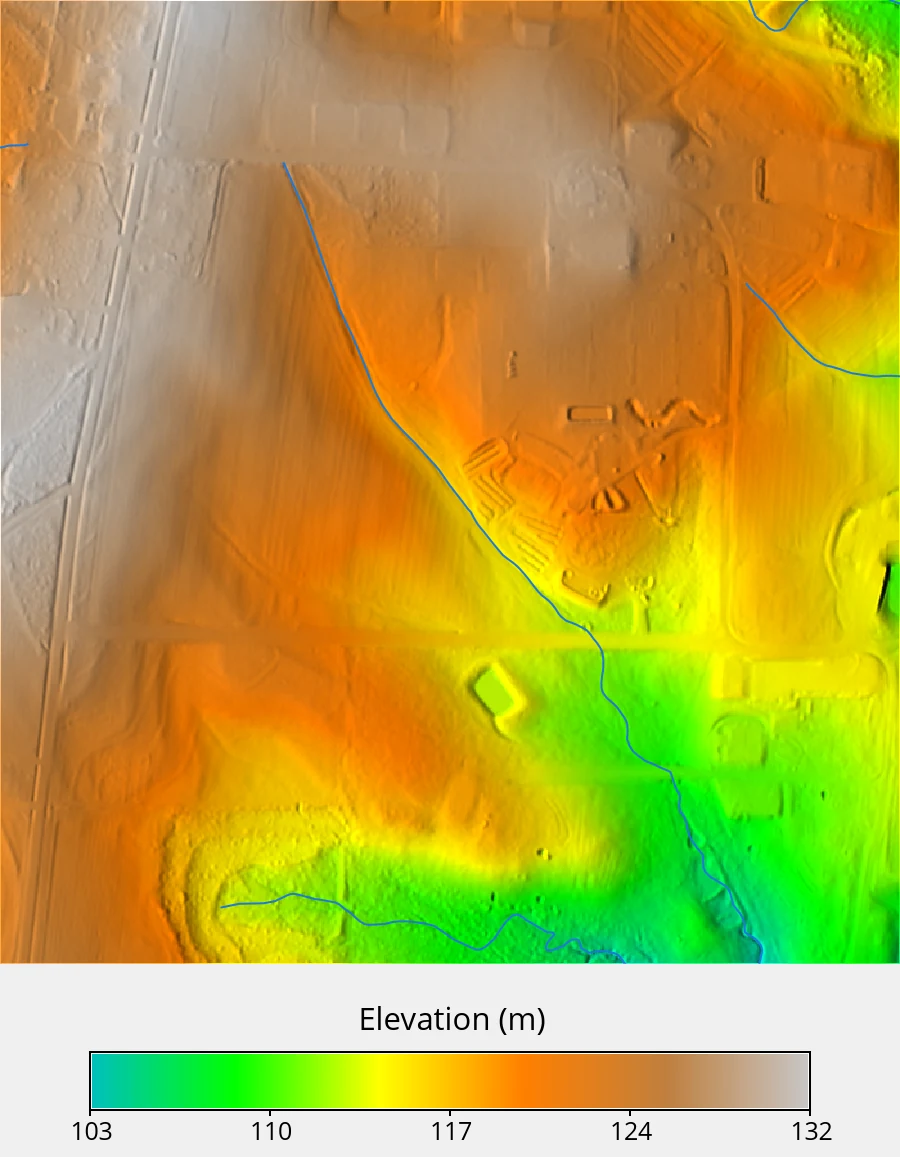

The packaged land cover raster was derived by combining lidar, NAIP
imagery, and OpenStreetMap roads. Its six classes (i.e., developed,
paved road, compacted road, herbaceous, forest, water) will supply the
surface roughness values later.

In [11]:
# Widen the region 500 m to the west so d.legend has empty map to sit in.
# The widened region is 1200 x 750 m, so the frame keeps that 1.6 aspect.
with gs.RegionManager(w="w-400"):
    lc = gj.Map(width=900, font=FONT, use_region=True)
    lc.d_shade(shade="relief", color="landcover", brighten=35)
    lc.d_graph(stdin=io.StringIO(BLANK_WEST))
    lc.d_legend(raster="landcover", title="Land cover",
        at=(15, 85, 4, 25), flags="nc",
        fontsize=18, title_fontsize=24, bgcolor="none"
    )
    lc.show()

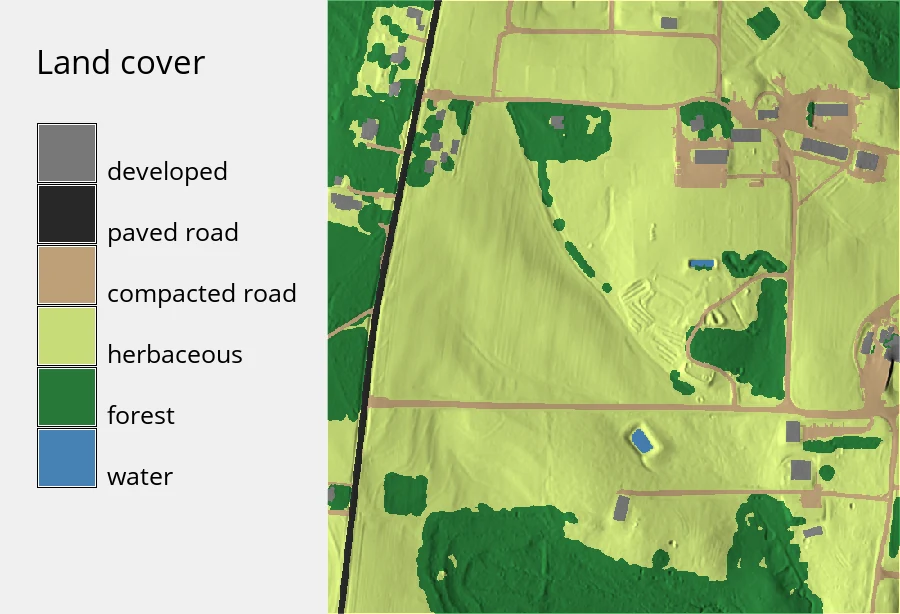

# Importing soil texture from SSURGO

The Soil Survey Geographic Database (SSURGO) is the USDA’s detailed soil
survey (Soil Survey Staff, Natural Resources Conservation Service,
United States Department of Agriculture, n.d.). It is distributed as map
unit polygons linked to tables of soil components and horizons, so it
needs aggregation before it can be used as raster model input.
`r.in.ssurgo` pulls the survey, aggregates the component and horizon
tables over a depth interval, and writes the result as rasters.

When `ssurgo_path` is left empty, the tool builds an area of interest
from the current computational region and queries the [Soil Data
Access](https://sdmdataaccess.nrcs.usda.gov/) (SDA) web service, so for
a 52 ha region no manual download is required.

In [12]:
tools.r_in_ssurgo(
    soils="ssurgo_soils",
    sand="sand",
    silt="silt",
    clay="clay",
    bulk_density="bd",
    ksat_r="ssurgo_ksat_r",
    hydgrp="hydgrp",
    mukey="mukey",
    hzdept_r=0,
    hzdepb_r=25.4,
)

`hzdept_r=0` and `hzdepb_r=25.4` request a depth-weighted average over
the top 25.4 cm (i.e., 10 inches), the layer that governs infiltration
during a short storm. The SDA query takes a couple of minutes.

> **SDA or a local archive?**
>
> `r.in.ssurgo` reads SSURGO two ways. Leaving `ssurgo_path` empty
> queries the SDA web service for the current region, which is what we
> do here. Supplying a local archive instead, either a Web Soil Survey
> area export or a state-wide gSSURGO database, avoids the network and
> scales to large areas. The [SIMWE parallelization
> tutorial](../parallelization/SIMWE_parallelization.qmd) uses the local
> mode with a state-wide gSSURGO file. The local mode works best with
> the `duckdb` Python package, and falls back to a SQLite backend
> without it.

The three texture separates (i.e., sand, silt, and clay) are the
required ROSETTA inputs. Bulk density is optional and improves the
estimate.

All three share one 0 to 70% color table, so the panels show their
relative size as well as their internal variation.

In [13]:
rules = """0 241:230:218
12 222:200:177
23 202:171:138
35 177:140:99
47 149:109:64
58 118:80:36
70 84:53:15
nv 255:255:255
"""
for name in ["sand", "silt", "clay"]:
    tools.r_colors(map=name, rules="-", stdin=io.StringIO(rules))
    m = gj.Map(width=700, height=750, font=FONT)
    m.d_shade(shade="relief", color=name, brighten=25)
    m.show()

# one legend for all three, on its own frame
leg = gj.Map(width=1200, height=150, font=FONT)
leg.d_legend(raster="sand", title="Fraction of mineral soil (%)", range=(0, 70),
             at=(30, 55, 6, 94), flags="st", fontsize=20, title_fontsize=24)
leg.show()

<table style="width:100%;">
<colgroup>
<col style="width: 33%" />
<col style="width: 33%" />
<col style="width: 33%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="33.3%"
data-layout-align="left">
<figure>
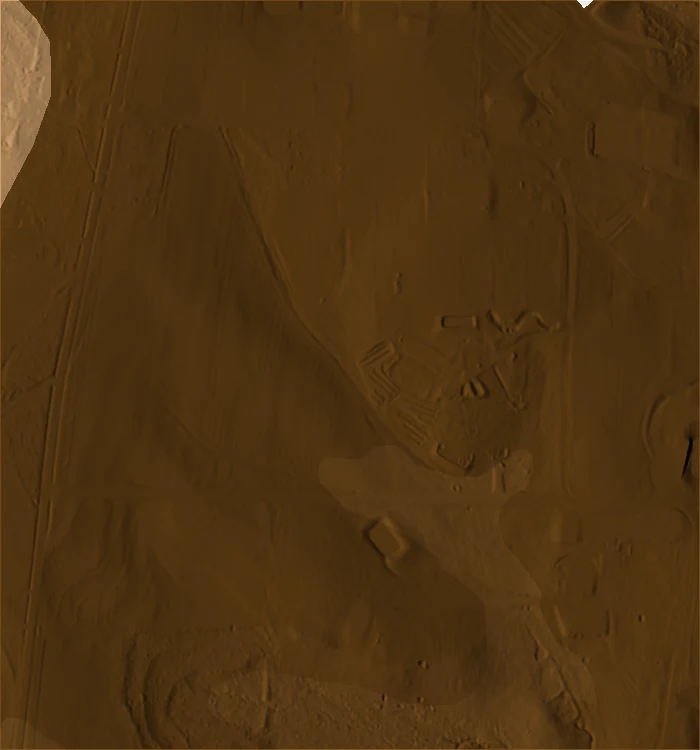
<figcaption aria-hidden="true">Sand</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="33.3%"
data-layout-align="left">
<figure>
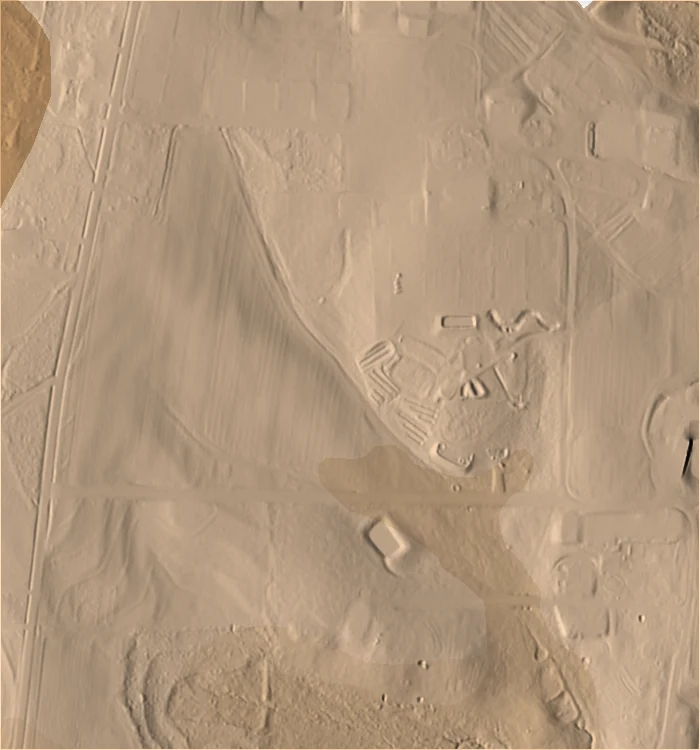
<figcaption aria-hidden="true">Silt</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="33.3%"
data-layout-align="left">
<figure>
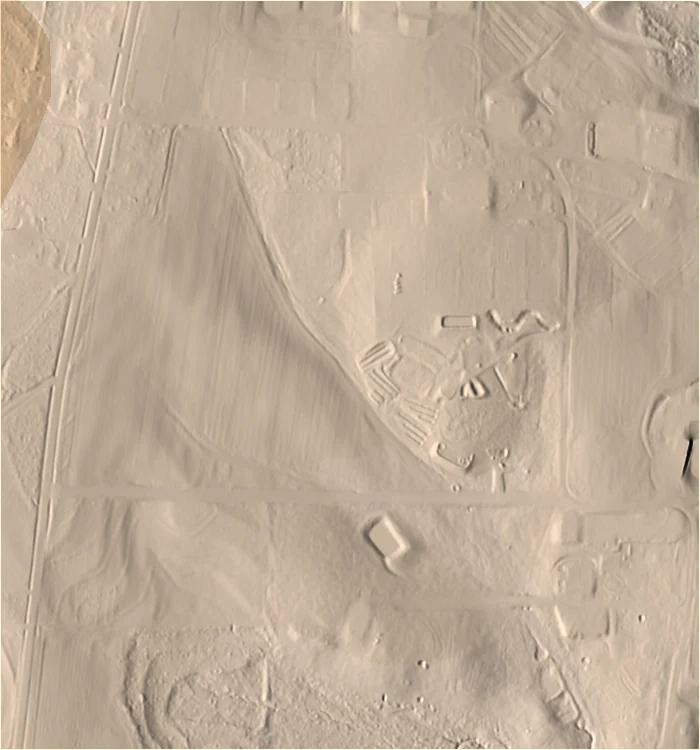
<figcaption aria-hidden="true">Clay</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

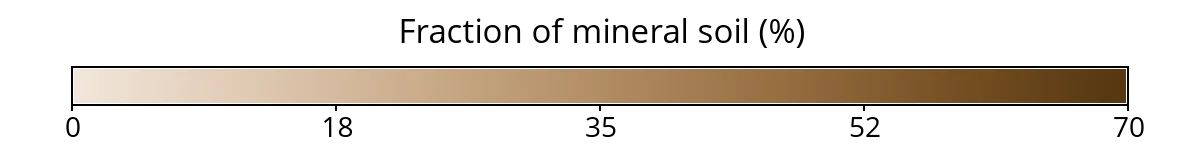

The site averages 67% sand and 12% clay. The texture rasters are
piecewise constant because SSURGO reports one value per map unit, and
seven map units cover the entire site (15 polygons, several of which
share a map unit key).

In [14]:
rows = []
for name in ["sand", "silt", "clay", "bd"]:
    s = tools.r_univar(map=name, format="json")
    rows.append({"raster": name, "min": s["min"], "max": s["max"], "mean": s["mean"]})

pd.DataFrame(rows).round(2)

| raster |   min |   max |  mean |
|:-------|------:|------:|------:|
| sand   | 40.00 | 68.00 | 67.20 |
| silt   | 20.00 | 37.00 | 20.92 |
| clay   | 10.00 | 23.00 | 11.89 |
| bd     |  1.38 |  1.58 |  1.58 |

# Estimating hydraulic parameters with ROSETTA

ROSETTA is a hierarchical pedotransfer model that estimates the
Mualem-van Genuchten parameters from soil texture (Schaap et al. 2001;
Genuchten 1980). `r.soils.rosetta` applies it cell by cell using the
recalibrated Rosetta3 coefficients (Zhang and Schaap 2017).

> **What is a pedotransfer function?**
>
> Measuring saturated hydraulic conductivity in the field is slow and
> expensive, so it is rarely mapped over large areas, while texture is
> recorded everywhere a soil survey goes. A pedotransfer function is a
> statistical model fit to soils where both quantities were measured,
> and it estimates the expensive property from the inexpensive one.
> ROSETTA was trained on roughly 2000 soil samples and estimates five
> parameters: residual and saturated water content (`theta_r`,
> `theta_s`), the van Genuchten shape parameters `alpha` and `n`, and
> saturated hydraulic conductivity (`ksat`).

The combination of inputs supplied selects the model version. Texture
alone gives model 2, adding bulk density gives model 3, and adding water
content at 33 kPa and 1500 kPa gives models 4 and 5. We have bulk
density, so this is a model 3 run. Only the outputs that are named get
computed.

In [15]:
tools.r_soils_rosetta(
    sand="sand",
    silt="silt",
    clay="clay",
    bulk_density="bd",
    ksat="ksat_rosetta",
    theta_s="theta_s",
    version=3,
    ksat_units="mm_per_hour",
)

ROSETTA reports conductivity in cm/day and `r.sim.water` expects mm/hr,
so `ksat_units="mm_per_hour"` has the tool convert the output.

In [16]:
ksat_rules = """0% 205:226:251
20% 158:197:244
40% 109:167:236
60% 57:135:229
80% 28:92:171
100% 13:54:107
nv 255:255:255
"""
tools.r_colors(map="ksat_rosetta", rules="-", stdin=io.StringIO(ksat_rules))

with gs.RegionManager(s="s-150"):
    m = gj.Map(width=900, height=1157, font=FONT, use_region=True)
    m.d_shade(shade="relief", color="ksat_rosetta", brighten=25)
    m.d_graph(stdin=io.StringIO(BLANK))
    m.d_legend(raster="ksat_rosetta", at=(4, 9, 10, 90), flags="st",
               title="Saturated hydraulic conductivity (mm/hr)",
               fontsize=18, title_fontsize=22)
    m.show()

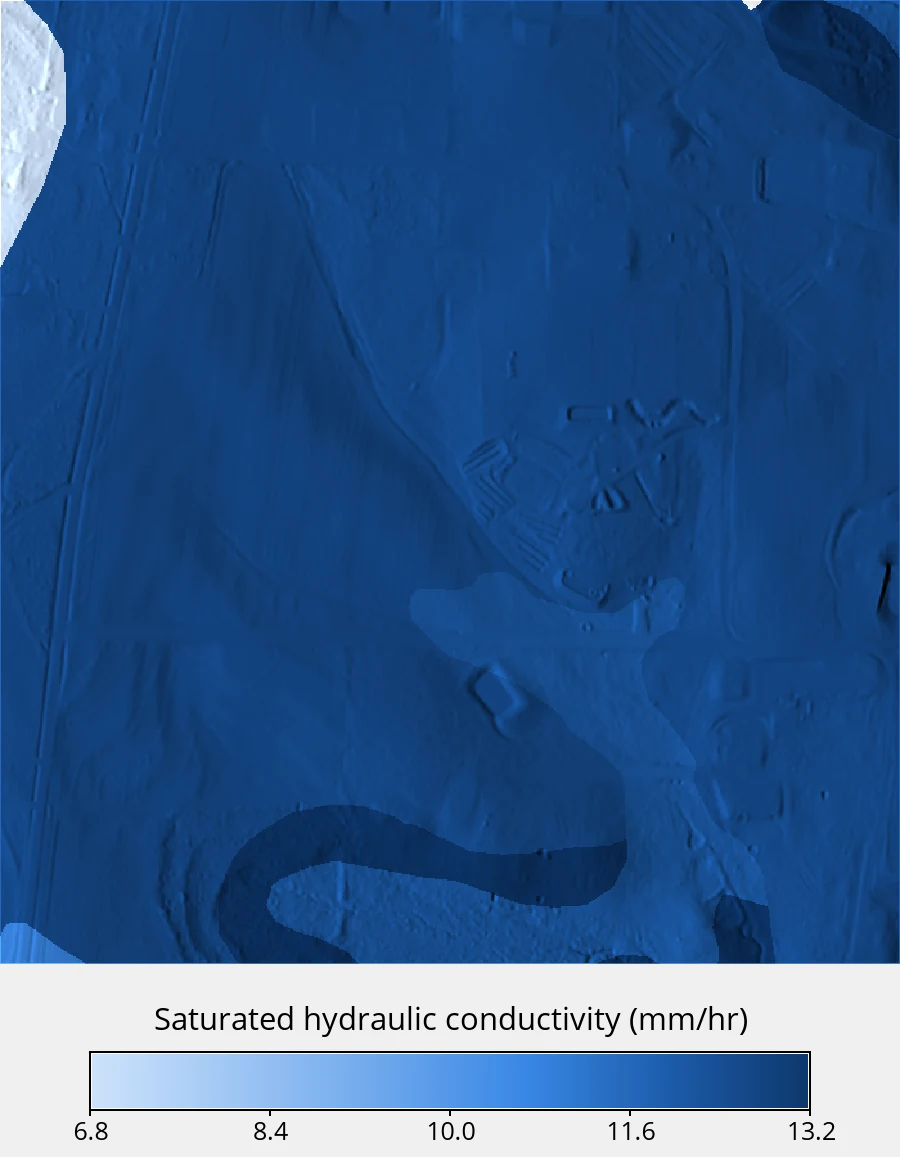

Estimated conductivity ranges from 6.8 to 13.2 mm/hr. The lowest values
fall on the map unit carrying 23% clay, which follows the drainage line
through the southern half of the site. Saturated water content (i.e.,
the pore space available to hold water) ranges from 0.36 to 0.41
cm³/cm³.

In [17]:
theta_rules = """0% 220:240:236
17% 176:218:209
33% 134:192:181
50% 96:164:152
67% 60:132:121
83% 31:101:91
100% 12:70:62
nv 255:255:255
"""
tools.r_colors(map="theta_s", rules="-", stdin=io.StringIO(theta_rules))

with gs.RegionManager(s="s-150"):
    m = gj.Map(width=900, height=1157, font=FONT, use_region=True)
    m.d_shade(shade="relief", color="theta_s", brighten=25)
    m.d_graph(stdin=io.StringIO(BLANK))
    m.d_legend(raster="theta_s", title="Saturated water content (cm3/cm3)",
               at=(4, 9, 10, 90), flags="st", fontsize=18, title_fontsize=22)
    m.show()

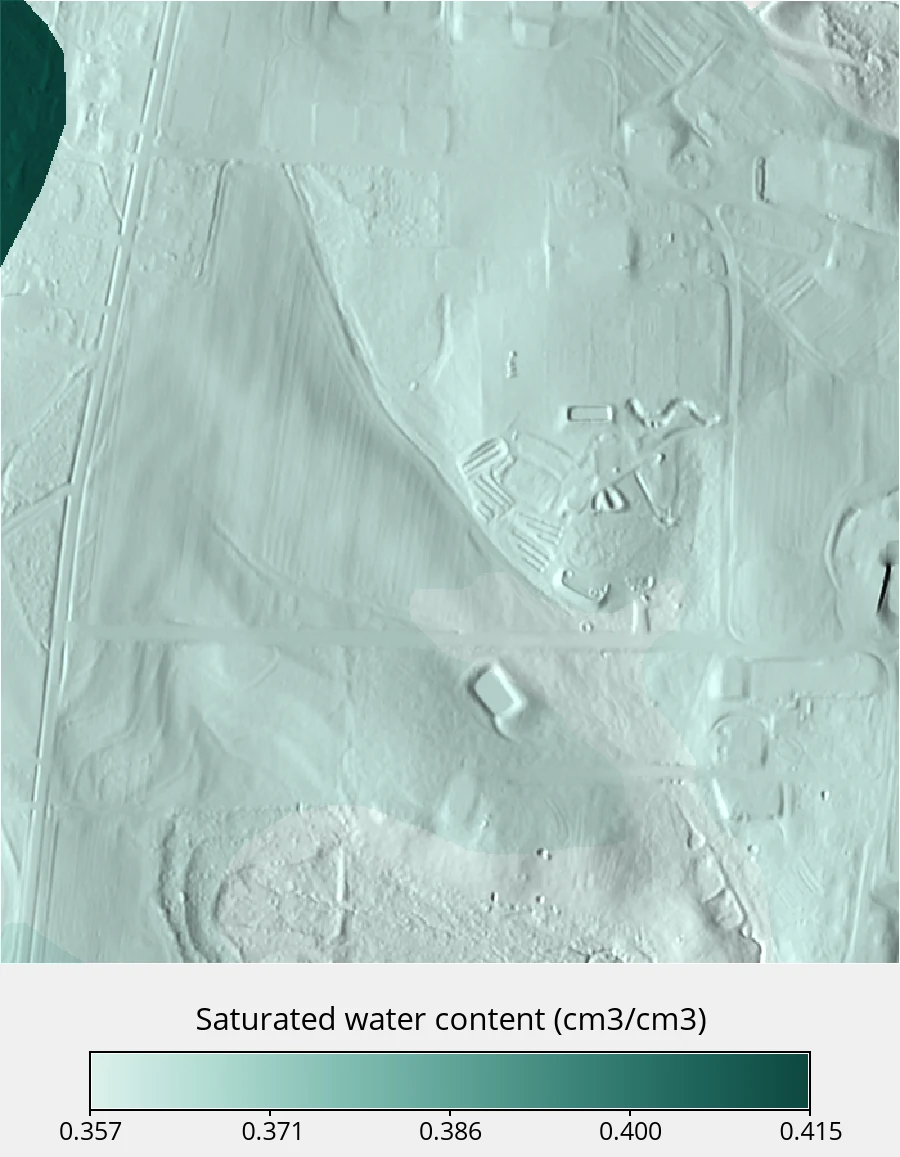

## Comparing against the Ksat reported by SSURGO

SSURGO reports a representative saturated hydraulic conductivity of its
own, imported above as `ssurgo_ksat_r`. We compare the two on a shared
absolute color scale.

In [18]:
rows = []
for name in ["ksat_rosetta", "ssurgo_ksat_r"]:
    s = tools.r_univar(map=name, format="json")
    rows.append({"raster": name, "min": s["min"], "max": s["max"], "mean": s["mean"]})

pd.DataFrame(rows).round(2)

| raster        |   min |    max |  mean |
|:--------------|------:|-------:|------:|
| ksat_rosetta  |  6.79 |  13.24 | 12.41 |
| ssurgo_ksat_r | 32.40 | 100.80 | 99.84 |

Both panels share one absolute color table, log-spaced over the NRCS
class range.

In [19]:
rules = """3 205:226:251
6 158:197:244
12 109:167:236
25 57:135:229
50 28:92:171
110 13:54:107
nv 255:255:255
"""
for name in ["ksat_rosetta", "ssurgo_ksat_r"]:
    tools.r_colors(map=name, rules="-", stdin=io.StringIO(rules))
    m = gj.Map(width=700, height=750, font=FONT)
    m.d_shade(shade="relief", color=name, brighten=22)
    m.show()

leg = gj.Map(width=1200, height=150, font=FONT)
leg.d_legend(raster="ksat_rosetta", range=(3, 110), at=(30, 55, 6, 94), flags="stl",
             title="Saturated hydraulic conductivity (mm/hr)",
             fontsize=20, title_fontsize=24)
leg.show()

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
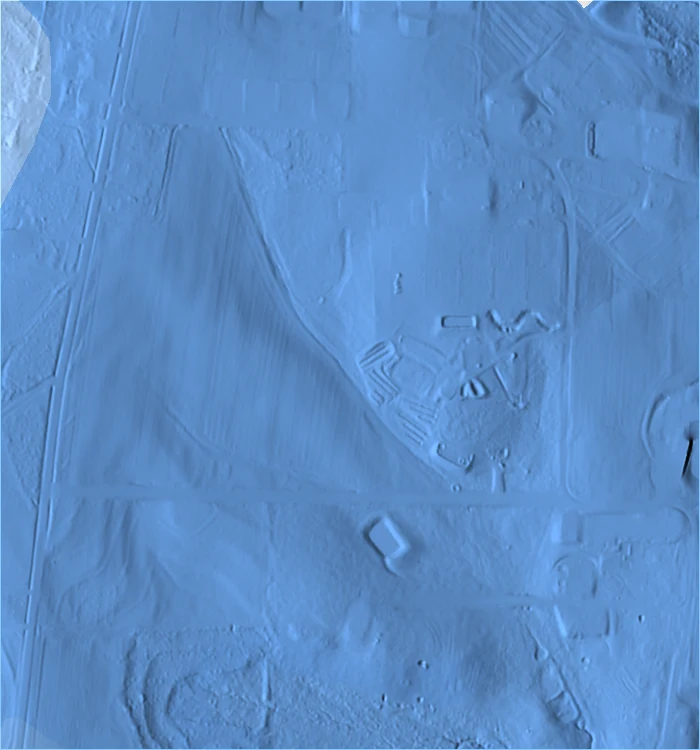
<figcaption aria-hidden="true">ROSETTA estimate</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="50.0%"
data-layout-align="left">
<figure>
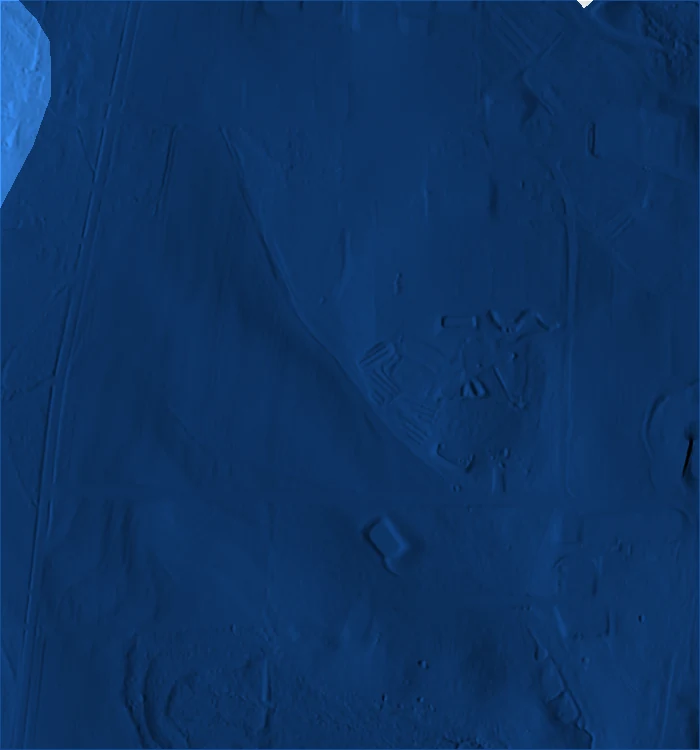
<figcaption aria-hidden="true">SSURGO reported</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

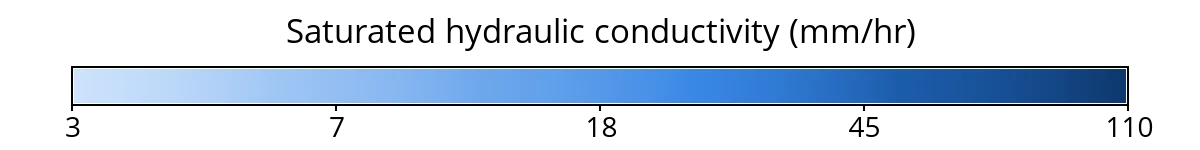

SSURGO’s representative value averages about eight times higher than the
ROSETTA estimate. These differences are reflective of the different
methods used to produce the estimates, as neither represent direct field
measurments of the site. SSURGO’s is a soil scientist’s estimate for the
component, anchored to field observation and conductivity class ranges,
while ROSETTA’s is a regression on texture and bulk density.

> **Pedotransfer estimates carry uncertainty**
>
> Saturated hydraulic conductivity varies over orders of magnitude and
> is difficult to constrain, so a large spread between two estimates is
> not unusual. Running `r.soils.rosetta` with the `-u` flag produces
> per-parameter standard deviation maps.

ROSETTA is also nonlinear, so applying it to depth-averaged texture does
not give the same result as applying it per horizon and averaging
afterward. We requested texture already averaged over the top 25.4 cm,
so the estimate inherits that approximation.

# Preparing the SIMWE inputs

SIMWE solves the shallow water flow equation using a path sampling
(i.e., walker-based) method (Mitas and Mitasova 1998; Mitasova et al.
2004). Besides elevation it needs a surface roughness map, a rainfall
rate, and an infiltration rate. The partial derivatives of the surface
are computed internally.

Manning’s n comes from land cover through the
[r.manning](https://grass.osgeo.org/grass-stable/manuals/addons/r.manning.html)
addon, which ships coefficients for NLCD and ESA WorldCover and takes a
`code,n` rules file for anything else. The SECREF classes are custom, so
we supply our own, ranging from 0.011 for pavement to 0.20 for forest
floor.

In [20]:
tools.g_extension(extension="r.manning")

rules = """# code,n
1,0.05
2,0.011
3,0.02
4,0.10
5,0.20
6,0.03
"""
rules_file = Path("manning_rules.csv")
rules_file.write_text(rules)

tools.r_manning(
    input="landcover",
    output="manning",
    landcover="custom",
    rules=str(rules_file),
)

In [21]:
manning_colors = """0.011 142:191:148
0.02 107:165:115
0.03 77:138:87
0.05 54:110:64
0.10 34:83:44
0.2001 19:57:27
nv 255:255:255
"""
tools.r_colors(map="manning", rules="-", stdin=io.StringIO(manning_colors))

with gs.RegionManager(s="s-150"):
    m = gj.Map(width=900, height=1157, font=FONT, use_region=True)
    m.d_shade(shade="relief", color="manning", brighten=35)
    m.d_graph(stdin=io.StringIO(BLANK))
    m.d_legend(raster="manning", title="Manning's n", range=(0.011, 0.2),
               at=(4, 9, 10, 90), flags="stl", fontsize=18, title_fontsize=22)
    m.show()

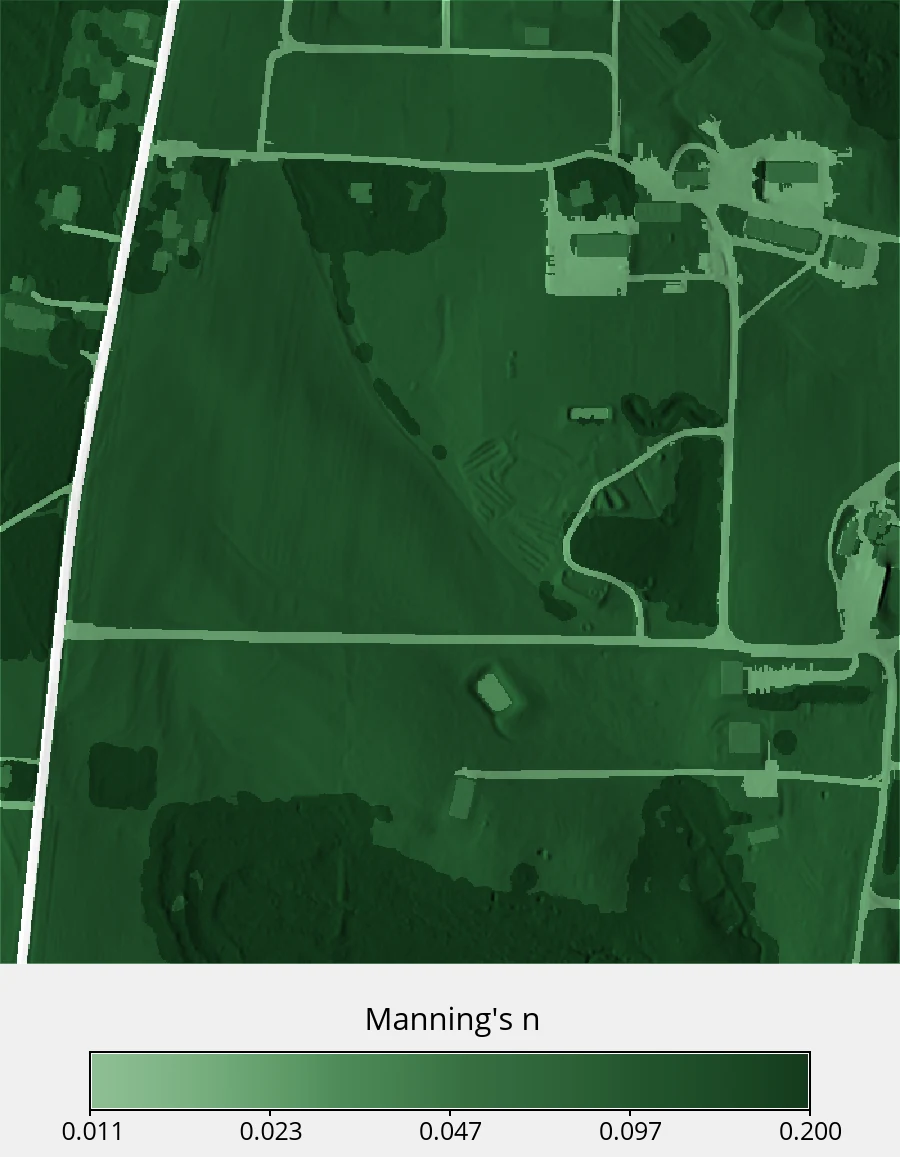

The SSURGO polygons leave 72 cells out of 525,000 without soil data.
`r.sim.water` applies no infiltration where the `infil` map is NULL, so
those cells would shed water as if they were paved. We fill them with
the site mean.

In [22]:
tools.r_mapcalc(expression="ksat_fill = if(isnull(ksat_rosetta), 12.4, ksat_rosetta)")

# Running the simulations

All three runs use a 54 mm/hr rainfall rate held for 60 minutes,
approximately a 10-year, 1-hour storm for Raleigh. The infiltration
input is the only thing that changes between them.

> **`rain` and `infil` act at different points**
>
> The `rain` parameter takes the rainfall excess rate (rainfall minus
> infiltration). The subtraction occurs before the run, so the removed
> water never enters the flow at all.
>
> `infil` applies to water that is already moving across a cell, which
> drinks from it at a fixed rate. That is what captures runoff generated
> on pavement losing volume as it crosses a lawn downslope, and it is
> what we use here.
>
> Neither rate responds to the soil filling up. Both stay constant for
> the whole simulation.

The first run is the baseline a modeler gets with no soil data at all.
Leaving `infil` off defaults it to zero, so every millimeter of rain
stays on the surface.

In [23]:
tools.r_sim_water(
    elevation="elevation",
    rain_value=54,
    man="manning",
    depth="depth_noinfil",
    discharge="disch_noinfil",
    duration=60,
    output_step=60,
    random_seed=7,
    nprocs=6,
)

The second run uses the ROSETTA field.

In [24]:
tools.r_sim_water(
    elevation="elevation",
    rain_value=54,
    infil="ksat_fill",
    man="manning",
    depth="depth_rosetta",
    discharge="disch_rosetta",
    duration=60,
    output_step=60,
    random_seed=7,
    nprocs=6,
)

> **Simulation run time**
>
> Each run covers 525,000 cells with roughly a million walkers, so
> expect several minutes per simulation. Increase `nprocs` if more cores
> are available, and reduce `duration` to 20 minutes while adjusting the
> workflow.

The third run uses the Ksat reported by SSURGO.

In [25]:
tools.r_mapcalc(
    expression="ssurgo_ksat_fill = if(isnull(ssurgo_ksat_r), 99.8, ssurgo_ksat_r)"
)
tools.r_sim_water(
    elevation="elevation",
    rain_value=54,
    infil="ssurgo_ksat_fill",
    man="manning",
    depth="depth_ssurgo",
    discharge="disch_ssurgo",
    duration=60,
    output_step=60,
    random_seed=7,
    nprocs=6,
)

# Results

The three runs share one color table, with breaks spaced logarithmically
because depth spans four orders of magnitude.

In [26]:
rules = """0 226:197:164
0.002 191:172:131
0.008 127:154:132
0.03 77:128:131
0.12 39:99:120
0.45 10:70:103
2.1 3:42:76
nv 255:255:255
"""
for name in ["depth_noinfil", "depth_rosetta", "depth_ssurgo"]:
    tools.r_colors(map=name, rules="-", stdin=io.StringIO(rules))
    m = gj.Map(width=700, height=750, font=FONT)
    m.d_shade(shade="relief", color=name, brighten=50)
    m.d_vect(map="streams", color="90:90:90", width=1)
    m.show()

leg = gj.Map(width=1200, height=150, font=FONT)
leg.d_legend(raster="depth_rosetta", title="Water depth (m)", range=(0.001, 2.1),
             at=(30, 55, 6, 94), flags="stl", fontsize=20, title_fontsize=24)
leg.show()

<table style="width:100%;">
<colgroup>
<col style="width: 33%" />
<col style="width: 33%" />
<col style="width: 33%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="33.3%"
data-layout-align="left">
<figure>
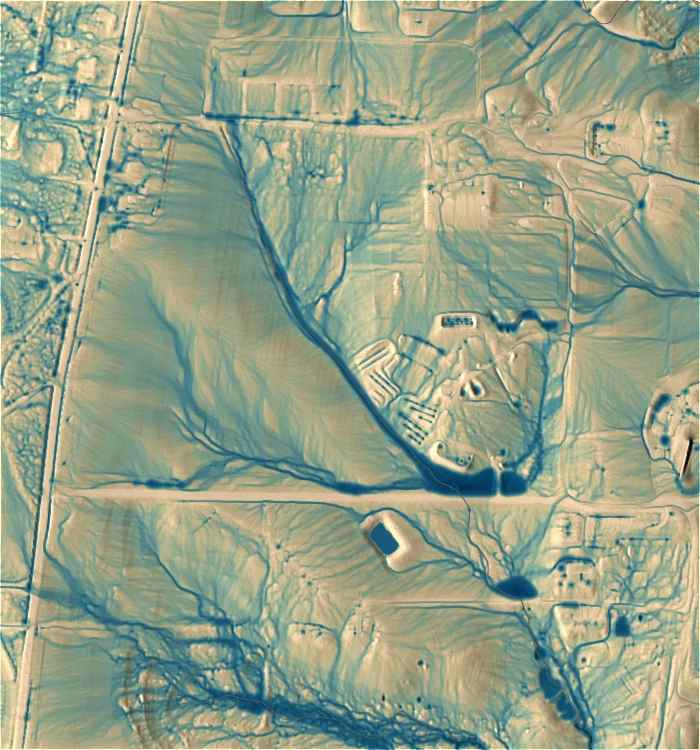
<figcaption aria-hidden="true">No infiltration</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="33.3%"
data-layout-align="left">
<figure>
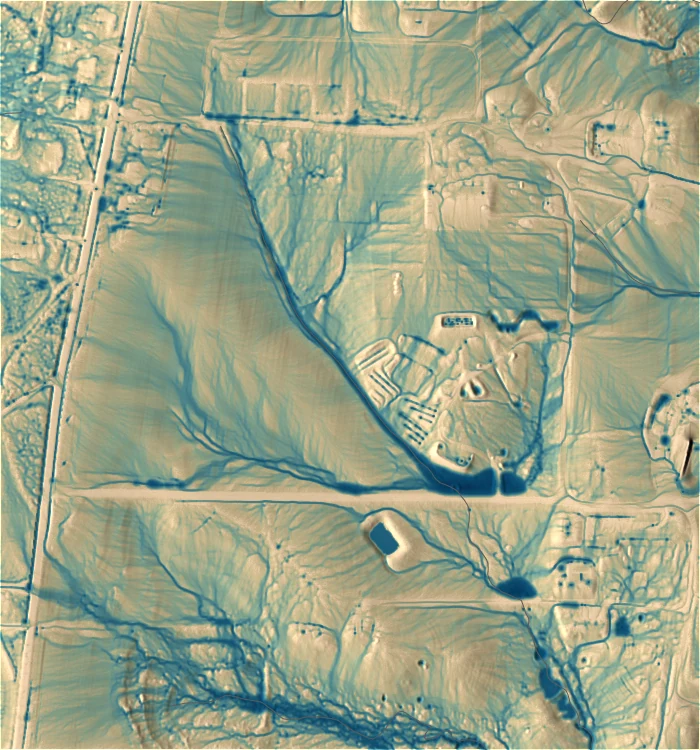
<figcaption aria-hidden="true">ROSETTA field</figcaption>
</figure>
</div></td>
<td style="text-align: left;"><div width="33.3%"
data-layout-align="left">
<figure>
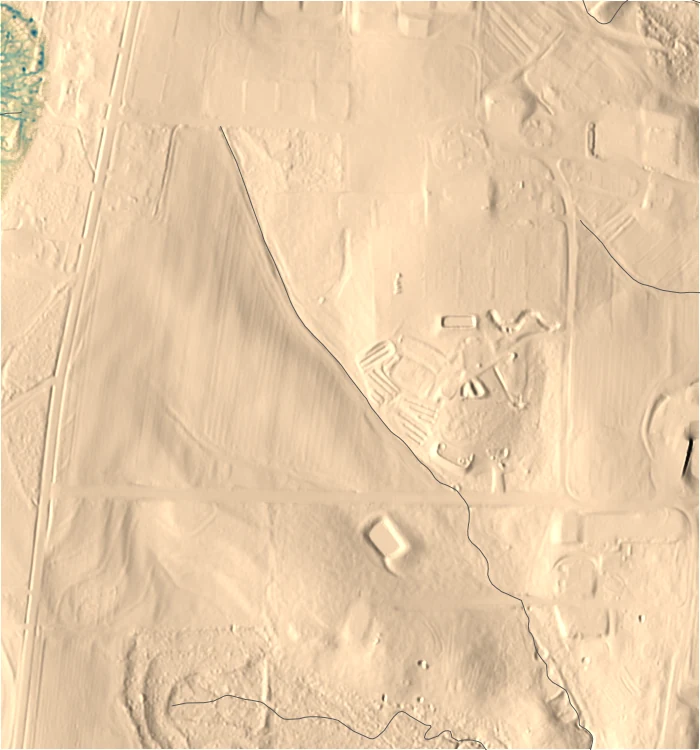
<figcaption aria-hidden="true">SSURGO Ksat</figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

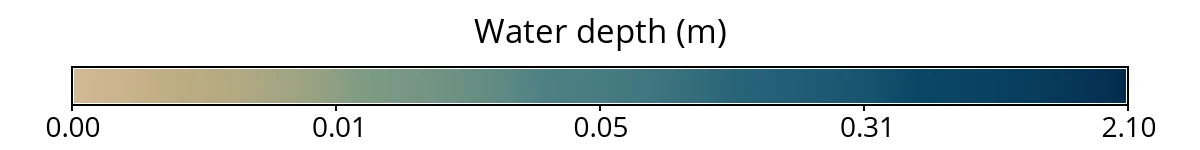

In [27]:
rows = []
for name in ["depth_noinfil", "depth_rosetta", "depth_ssurgo"]:
    s = tools.r_univar(map=name, format="json")
    rows.append({"run": name, "mean depth (mm)": s["mean"] * 1000, "total": s["sum"]})

pd.DataFrame(rows).round(3)

| run           | mean depth (mm) |   total |
|:--------------|----------------:|--------:|
| depth_noinfil |          21.931 | 11513.7 |
| depth_rosetta |          18.509 |  9717.0 |
| depth_ssurgo  |           0.071 |    37.3 |

## ROSETTA infiltration against none

The ROSETTA field removed 15.6% of the surface water, dropping mean flow
depth from 21.9 mm to 18.5 mm. We map the difference to see where it
went.

In [28]:
tools.r_mapcalc(expression="depth_diff = depth_rosetta - depth_noinfil")

# Red where infiltration removed water, blue where it added, tan at no change.
# Breaks are tight near zero because 95% of cells fall within a centimetre of it.
diff_rules = """-0.30 103:0:13
-0.08 178:24:43
-0.02 214:96:77
-0.005 240:160:110
-0.001 226:200:150
0 219:194:122
0.001 180:205:220
0.01 33:102:172
nv 255:255:255
"""
tools.r_colors(map="depth_diff", rules="-", stdin=io.StringIO(diff_rules))

with gs.RegionManager(s="s-150"):
    m = gj.Map(width=900, height=1157, font=FONT, use_region=True)
    m.d_shade(shade="relief", color="depth_diff", brighten=50)
    m.d_graph(stdin=io.StringIO(BLANK))
    # -0.05 to 0.01 covers 99% of cells; losses run to -0.30, so the clipped
    # end is labelled over the bar. label_values puts a tick on zero.
    m.d_legend(raster="depth_diff", title="Depth difference (m)",
               range=(-0.05, 0.01), at=(4, 9, 10, 90), flags="st",
               label_values=[-0.04, -0.03, -0.02, -0.01, 0, 0.01],
               digits=2, fontsize=18, title_fontsize=22)
    # the clipped end gets its own axis label in place of a plain -0.05
    m.d_text(
        text="< -0.05", at=(10, 2.29), align="cc",
        color="black",
        size=2.1,
        font=FONT
        )
    m.show()

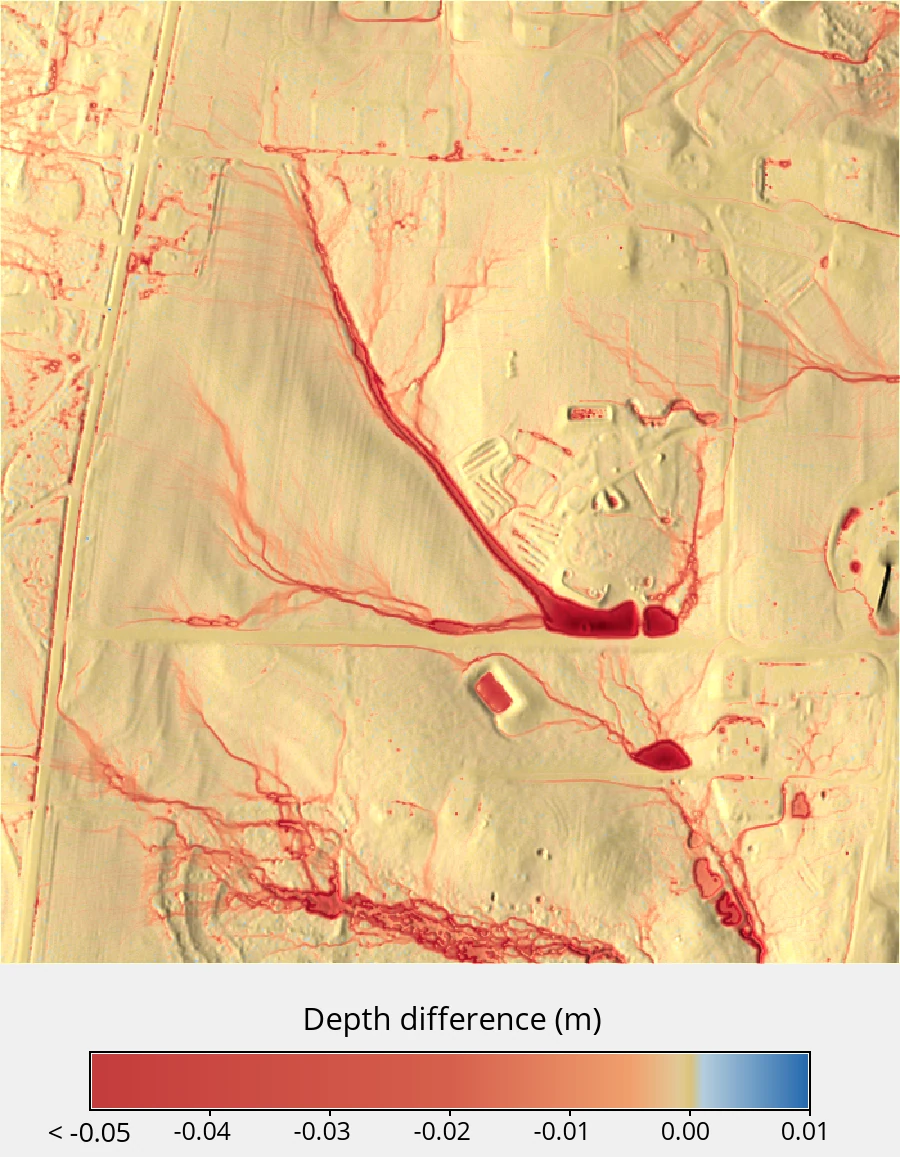

In [29]:
stats = tools.r_univar(map="depth_diff", format="json")
pd.DataFrame(
    [{key: stats[key] for key in ["min", "max", "mean", "stddev"]}]
).round(4)

|     min |    max |    mean | stddev |
|--------:|-------:|--------:|-------:|
| -0.2984 | 0.0096 | -0.0034 | 0.0122 |

The loss is concentrated where water collects. Cells in the ponds and
the main drainage line drop by up to 30 cm, while the sheet flow over
the plots loses almost nothing, since a cell only infiltrates from the
water crossing it.

> **The spatial pattern matters less than the level**
>
> The seven SSURGO map units at this site span only 6.8 to 13.2 mm/hr, a
> standard deviation of 0.7 mm/hr. Swapping that field for its own site
> mean of 12.4 mm/hr moves mean flow depth by about one tenth of one
> percent.

## ROSETTA Ksat compared to SSURGO Ksat

The SSURGO-driven run left 37 units of water on the surface against the
ROSETTA run’s 9717, a factor of 260. SSURGO’s representative
conductivity averages 99.8 mm/hr while the storm delivers 54 mm/hr, so
infiltration keeps pace with rainfall across most of the site and only
the wettest corner generates any flow depth.

Adding a soil-derived infiltration field to the model changed the result
by 16%. Choosing between two published estimates of that soil property
changed it by two orders of magnitude. Deciding between them requires a
field measurement of conductivity at the site.

# Assumptions and limitations

- Depth averaging over the top 25.4 cm discards horizon structure, and
  because ROSETTA is nonlinear the estimate is not equivalent to a
  per-horizon calculation.
- Ksat is the conductivity of an already saturated soil, and `infil`
  holds it constant for the whole run. Dry soil takes water faster than
  that, so these runs understate infiltration and overstate runoff early
  in the storm.
- Manning’s n values are assigned by land cover class from published
  tables rather than calibrated at this site.
- None of the runs are validated against observed discharge at SECREF,
  so the comparisons describe model sensitivity rather than model
  accuracy.

# Summary

We derived a spatially varying infiltration field from a soil survey and
used it to drive an overland flow simulation:

- `r.in.ssurgo` converts SSURGO map units into depth-weighted texture
  rasters, over the SDA web service for small areas or from a local
  archive for large ones.
- `r.soils.rosetta` applies the ROSETTA pedotransfer model to those
  rasters and writes saturated hydraulic conductivity in the units
  `r.sim.water` expects.
- `r.sim.water` takes that conductivity as its `infil` input.

At this site, adding a soil-derived infiltration field removed 16% of
the surface water, while exchanging one published conductivity estimate
for another changed it by a factor of 260. At this site the magnitude of
Ksat matters more than its spatial pattern of overland flow.

# See also

- [r.in.ssurgo](https://grass.osgeo.org/grass-stable/manuals/addons/r.in.ssurgo.html)
- [r.soils.rosetta](https://grass.osgeo.org/grass-stable/manuals/addons/r.soils.rosetta.html)
- [r.sim.water](https://grass.osgeo.org/grass-stable/manuals/r.sim.water.html)
- [Parallelization of overland flow and sediment transport
  simulation](../parallelization/SIMWE_parallelization.qmd)
- [SIMWE Soils
  Project](https://ncsu-geoforall-lab.github.io/NRCS_SIMWE/), the NRCS
  work this workflow comes out of (White et al., n.d.), with the same
  workflow at catchment scale for [Coweeta,
  NC](https://ncsu-geoforall-lab.github.io/NRCS_SIMWE/notebooks/ssurgo.html)
  and [Clay Center,
  KS](https://ncsu-geoforall-lab.github.io/NRCS_SIMWE/notebooks/ssurgo_clay_center.html)
- [SECREF sample dataset on
  Zenodo](https://doi.org/10.5281/zenodo.23017720)

# References

Genuchten, Martinus Th. van. 1980. “A Closed-Form Equation for
Predicting the Hydraulic Conductivity of Unsaturated Soils.” *Soil
Science Society of America Journal* 44 (5): 892–98.
<https://doi.org/10.2136/sssaj1980.03615995004400050002x>.

Mitas, Lubos, and Helena Mitasova. 1998. “Distributed Soil Erosion
Simulation for Effective Erosion Prevention.” *Water Resources Research*
34 (3): 505–16. <https://doi.org/10.1029/97WR03347>.

Mitasova, Helena, Chris Thaxton, Jaroslav Hofierka, Richard McLaughlin,
Amber Moore, and Lubos Mitas. 2004. “Path Sampling Method for Modeling
Overland Water Flow, Sediment Transport, and Short Term Terrain
Evolution in Open Source GIS.” In *Developments in Water Science*, vol.
55. Elsevier. <https://doi.org/10.1016/S0167-5648(04)80159-X>.

Petrasova, Anna. 2026. “GRASS Sample Dataset for SIMWE Model, NC State
University Sediment and Erosion Control Research and Education Facility,
North Carolina, USA.” Zenodo. <https://doi.org/10.5281/zenodo.23017720>.

Schaap, Marcel G., Feike J. Leij, and Martinus Th. van Genuchten. 2001.
“Rosetta: A Computer Program for Estimating Soil Hydraulic Parameters
with Hierarchical Pedotransfer Functions.” *Journal of Hydrology* 251
(3): 163–76. <https://doi.org/10.1016/S0022-1694(01)00466-8>.

Soil Survey Staff, Natural Resources Conservation Service, United States
Department of Agriculture. n.d. *Soil Survey Geographic Database
(SSURGO)*.
<https://www.nrcs.usda.gov/resources/data-and-reports/soil-survey-geographic-database-ssurgo>.

White, Corey T., Anna Petrasova, and Helena Mitasova. n.d. *SIMWE Soils
Project*. NC State University Center for Geospatial Analytics.
<https://ncsu-geoforall-lab.github.io/NRCS_SIMWE/>.

Zhang, Yonggen, and Marcel G. Schaap. 2017. “Weighted Recalibration of
the Rosetta Pedotransfer Model with Improved Estimates of Hydraulic
Parameter Distributions and Summary Statistics (Rosetta3).” *Journal of
Hydrology* 547 (April): 39–53.
<https://doi.org/10.1016/j.jhydrol.2017.01.004>.